In [126]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [132]:
device = 'cuda:0'
model = create_agent(cf, device)
# memories = create_memories(model.actor, cf.num_envs, device=device)

In [209]:
from memoryPerceiver.memory_perceiver.isaac.scaler import RunningStandardScaler
scaler = RunningStandardScaler(size=1, device=device)

In [212]:
scaler(torch.randn(20,240, device=device)+10, train=True)

tensor([[ 1.3473,  0.0829,  1.4300,  ..., -0.2399, -0.7330, -0.8052],
        [ 1.3130, -1.0138,  0.6695,  ...,  0.5649,  1.5872,  0.2166],
        [ 1.7160,  0.8198,  0.2871,  ..., -0.1184,  1.5872, -0.1907],
        ...,
        [ 0.2642, -0.3553, -0.0434,  ..., -1.0261, -0.7910,  0.8980],
        [-1.0127,  0.4363,  0.4661,  ...,  2.0707, -0.3023, -1.6358],
        [ 0.3550,  0.1616,  1.1163,  ..., -0.7445, -1.2661,  0.6969]],
       device='cuda:0')

In [213]:
scaler.running_mean.shape

torch.Size([1])

In [128]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
1

tensor([[-0.6149,  0.2724, -0.8778, -0.5603,  0.2771, -0.6685, -0.1334,  0.8201,
          0.3862, -0.2803, -0.6547,  0.7808,  0.0809,  0.8243, -0.2381,  0.8824,
         -0.0257,  0.0285,  0.8972,  0.1753,  0.4429,  0.7111, -0.6472,  0.5819,
          0.7596,  0.5323,  0.2247, -0.2066,  0.6491, -0.8477,  0.5031, -0.0233],
        [ 0.5569,  0.4630,  0.2575,  0.8535,  0.5941,  0.2899,  0.5800, -0.6570,
         -0.7602, -0.7138,  0.4900, -0.8760, -0.9646, -0.4027,  0.7483, -0.6960,
          0.8800,  0.7053, -0.5290,  0.5422, -0.7028, -0.6364,  0.5841,  0.1244,
          0.3192, -0.8073,  0.7520,  0.2364, -0.7956,  0.7320, -0.2723,  0.6356]],
       device='cuda:0')

In [144]:
device = 'cuda:0'
model = create_agent(cf, device)
states = {}
for i in range(4):
    states['observations'] = torch.randn(32, 1, 4, device=device)
actions, values, _, _ = model(states, None)

In [151]:
torch.randint(0,10, (1,)).item()

8

In [108]:
actions, _, values, _ = model(states, memories)
actions

tensor([[0.3633],
        [0.0259]], device='cuda:0')

In [50]:
loss_all=[]

In [51]:
for i in range(1000):
    tmp = torch.zeros(24, 1, 1, device=device)
    for i in range(4):
        states['observations'] = torch.rand(24, 1, 4, device=device)
    y_target =  states['observations'].detach().sum(dim=[1,2])

    _, values, _, _ = model(states, memories, torch.zeros(24, 1, 1, device=device))

    loss = F.mse_loss(values, y_target)
    print('std', values.std().item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # with torch.no_grad():  # No tracking of gradients during the update
    #     for param in model.parameters():
    #         if param.grad is not None:
    #             param -= 1e-4 * param.grad
    loss_all.append(loss.item())
    print('loss',loss.item())

std 0.0027623807545751333
loss 4.889331817626953
std 0.002512661973014474
loss 3.808967351913452
std 0.0017973160138353705
loss 3.9909873008728027
std 0.0013266924070194364
loss 3.0004849433898926
std 0.001246535568498075
loss 3.881093978881836
std 0.0007278253906406462
loss 3.4839205741882324
std 0.0007890188717283309
loss 3.0278499126434326
std 0.0006235623150132596
loss 2.4113197326660156
std 0.0005720852059312165
loss 2.6564180850982666
std 0.0005717959138564765
loss 3.0556812286376953
std 0.0005915014189668
loss 2.346067190170288


std 0.0006242173258215189
loss 2.0259928703308105
std 0.0005378753412514925
loss 1.8887608051300049
std 0.0007246749592013657
loss 1.6660490036010742
std 0.0007763992180116475
loss 1.3712708950042725
std 0.000813233491498977
loss 1.1592189073562622
std 0.0008810245199128985
loss 1.23737370967865
std 0.0008357919869013131
loss 0.8446659445762634
std 0.0005056588561274111
loss 0.8056349754333496
std 0.0010229161707684398
loss 0.7262055277824402
std 0.0009010068606585264
loss 0.7979158163070679
std 0.000889916205778718
loss 0.8362158536911011
std 0.000919849204365164
loss 0.49672502279281616
std 0.0008769881678745151
loss 0.3646601438522339
std 0.0008412782335653901
loss 0.343106746673584
std 0.001000399817712605
loss 0.5159085988998413
std 0.0008692544652149081
loss 0.5405247211456299
std 0.0010860217735171318
loss 0.25847697257995605
std 0.0009357792441733181
loss 0.36858803033828735
std 0.0008476389921270311
loss 0.38728731870651245
std 0.001103140995837748
loss 0.35231876373291016
std

In [38]:
from matplotlib import pyplot as plt

In [34]:
print(y_target[:5])

tensor([2.3809, 1.8877, 1.0047, 2.5893, 0.6357], device='cuda:0')


In [35]:
print(values[:20])

tensor([2.6062, 1.7422, 1.5893, 1.6826, 1.4687, 1.5767, 1.6690, 2.6060, 1.6801,
        2.6368, 1.9303, 1.5252, 1.6414, 1.5201, 2.6483, 1.5580, 1.4705, 1.5879,
        2.3985, 1.6067], device='cuda:0', grad_fn=<SliceBackward0>)


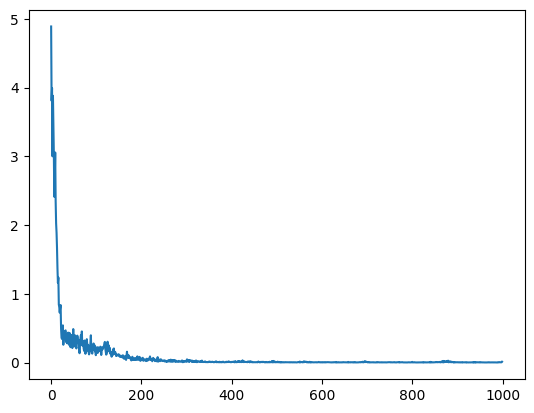

In [52]:
plt.plot(loss_all)